# CNN, LSTM, and GRU with PyTorch

Compare binary fall/non-fall classifiers on the selected amplitude sequence datasets. Inputs preserve the selected sequence grid and combine the four receiver views. The attempt-level split keeps overlapping windows and durations together; it does not establish participant- or session-independent performance. Fall targets follow action cues, and centered filtering uses future samples.

`DEVICE = "auto"` selects CUDA when available and otherwise uses CPU. Set `"cuda"` to require a GPU or `"cpu"` to use CPU explicitly. The optional 2-second Akmal pilot and full-data training are controlled independently. CNN, LSTM, and GRU have separate settings and run cells below. Existing outputs may be from previous runs.

## Setup and experiment settings

For CPU: `uv sync --inexact --extra analysis --extra detection --extra notebook`. For an NVIDIA GPU on Linux or Windows: `uv sync --inexact --extra analysis --extra cuda --extra notebook`. These extras select different PyTorch wheels and cannot be enabled together. Restart the project kernel after changing environments. The CUDA 13.0 wheel requires a compatible NVIDIA driver and GPU.

In [1]:
import json
import os
import sys
from datetime import UTC, datetime
from pathlib import Path

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import polars as pl
from IPython.display import display

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/fall_detection").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fall_detection.analysis.sequence_training_data import (
    SegmentStore,
    fit_normalizer,
    load_sequence_index,
    split_sequence_attempts,
)

DATASETS = ("khaelano", "akmal", "continuous_non_fall")
DURATIONS = (2, 4, 6)
SPLIT_SEED = 42
TEST_FRACTION = 0.2
VALIDATION_FRACTION = 0.2
SAMPLE_RATE = 120  # 96 or 120 Hz
DATA_ROOT = PROJECT_ROOT / f"data/processed/amplitude_sequence/{SAMPLE_RATE}hz"
PYTORCH_RUN = (
    PROJECT_ROOT
    / "artifacts/notebooks/03_training"
    / datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
)
CPU_THREADS = 4
BATCH_SIZE = 32  # Reduce if the CUDA device runs out of memory.
DEVICE = "cuda"  # "auto", "cpu", or "cuda"; "cuda" fails if unavailable
PILOT_DURATION = 2
RUN_PILOT = False
RUN_FULL_TRAINING = True
MODEL_RUN = PROJECT_ROOT / "models/sequence" / PYTORCH_RUN.name
print("PyTorch output:", PYTORCH_RUN, "requested device:", DEVICE)

## Models and training

The following cells define the models and training loop used by the pilot and full-data runs.

In [2]:
import hashlib
import marshal
import platform
import random
from dataclasses import asdict, dataclass, replace
from time import perf_counter

import numpy as np
import torch
from torch import nn

from fall_detection.analysis.sequence_device_cache import (
    DeviceSequenceDataset,
    prepare_device_dataset,
    training_batches,
)
from fall_detection.analysis.sequence_training_data import (
    Normalizer,
    SequenceDataset,
)

try:
    import resource
except ImportError:  # Windows does not provide resource.getrusage.
    resource = None

In [3]:
class TorchCNN(nn.Module):
    """Two temporal convolutions and a pooled binary head."""

    def __init__(self, features: int, hidden: int) -> None:
        super().__init__()
        self.conv1 = nn.Conv1d(features, hidden, 5, padding=2)
        self.conv2 = nn.Conv1d(hidden, hidden, 3, padding=1)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        hidden = self.conv1(x.transpose(1, 2)).relu()
        return self.head(self.conv2(hidden).relu().mean(dim=2)).flatten()

In [4]:
class TorchLSTM(nn.Module):
    """Single-layer full-sequence LSTM with a binary head."""

    def __init__(self, features: int, hidden: int) -> None:
        super().__init__()
        self.rnn = nn.LSTM(features, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output, _ = self.rnn(x)
        return self.head(output[:, -1]).flatten()

In [5]:
class TorchGRU(nn.Module):
    """Single-layer full-sequence reset-after GRU with a binary head."""

    def __init__(self, features: int, hidden: int) -> None:
        super().__init__()
        self.rnn = nn.GRU(features, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output, _ = self.rnn(x)
        return self.head(output[:, -1]).flatten()

In [6]:
MODELS = {"cnn": TorchCNN, "lstm": TorchLSTM, "gru": TorchGRU}


@dataclass(frozen=True)
class SequenceTrainingConfig:
    """Training settings for sequence models."""

    seed: int = 42
    duration: int = 2
    epochs: int = 3
    batch_size: int = 32
    hidden_size: int = 64
    learning_rate: float = 0.001
    clip_norm: float = 1.0
    cpu_threads: int = 4
    patience: int = 3
    device: str = "auto"
    input_cache_gib: float = 12.0
    device_cache_gib: float = 4.0
    device_reserve_gib: float = 4.0

In [7]:
def _rss_bytes() -> int | None:
    """Return peak resident memory on Linux, or None when unavailable."""
    if resource is None or platform.system() != "Linux":
        return None
    return int(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss) * 1024


def _cpu_name() -> str:
    """Read the host CPU model when the platform helper returns an empty name."""
    if Path("/proc/cpuinfo").is_file():
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    return platform.processor()


def _evaluate(
    model: nn.Module,
    dataset: SequenceDataset | DeviceSequenceDataset,
    batch_size: int,
    device: torch.device,
) -> dict:
    model.eval()
    targets, probabilities = [], []
    started = perf_counter()
    with torch.inference_mode():
        for values, rows in training_batches(dataset, batch_size):
            logits = model(
                torch.as_tensor(values).to(device, non_blocking=device.type == "cuda")
            )
            probabilities.append(torch.sigmoid(logits))
            targets.extend(int(row["target"]) for row in rows)
    probabilities = (
        torch.cat(probabilities).cpu().numpy() if probabilities else np.empty(0)
    )
    labels = np.asarray(targets, dtype=np.int8)
    predicted = np.asarray(probabilities) >= 0.5
    true_positive = int(np.count_nonzero(predicted & (labels == 1)))
    false_positive = int(np.count_nonzero(predicted & (labels == 0)))
    false_negative = int(np.count_nonzero(~predicted & (labels == 1)))
    denominator = 2 * true_positive + false_positive + false_negative
    precision_denominator = true_positive + false_positive
    recall_denominator = true_positive + false_negative
    return {
        "windows": len(labels),
        "accuracy": float(np.mean(predicted == labels)) if len(labels) else 0.0,
        "fall_precision": true_positive / precision_denominator
        if precision_denominator
        else 0.0,
        "fall_recall": true_positive / recall_denominator
        if recall_denominator
        else 0.0,
        "fall_f1": 2 * true_positive / denominator if denominator else 0.0,
        "seconds": perf_counter() - started,
    }

In [8]:
def train_models(
    frame_path: Path,
    normalizer_path: Path,
    output: Path,
    config: SequenceTrainingConfig,
    *,
    model_kind: str | None = None,
    expected_dataset: str | None = None,
    data_root: Path | None = None,
    model_output: Path | None = None,
) -> dict:
    """Train one or all PyTorch models on a saved v2 split and normalizer.

    Args:
        frame_path: Saved attempt-level split with absolute segment paths.
        normalizer_path: Statistics fitted on this split's training windows.
        output: Directory for local run metrics.
        model_output: Separate model bundle directory; defaults to output for callers.
        config: Batch, model, optimization, and CPU thread settings.
        model_kind: Optional model name; None trains all three.
        expected_dataset: Restrict a pilot to one named dataset.
        data_root: Rebase saved signal paths to this v2 dataset directory.

    Returns:
        Runtime and validation summaries for CNN, LSTM, and GRU.
    """
    frame_path, normalizer_path, output = (
        frame_path.resolve(),
        normalizer_path.resolve(),
        output.resolve(),
    )
    model_output = output if model_output is None else model_output.resolve()
    model_output.mkdir(parents=True, exist_ok=True)
    frame = pl.read_parquet(frame_path).filter(pl.col("duration") == config.duration)
    if data_root is not None:
        root = data_root.resolve()

        def signal_path(row: dict) -> str:
            path = (root / row["dataset"] / row["signal"]).resolve()
            if not path.is_relative_to(root):
                raise ValueError("Signal path escapes the dataset root")
            return str(path)

        frame = frame.with_columns(
            pl.struct("dataset", "signal")
            .map_elements(signal_path, return_dtype=pl.String)
            .alias("path")
        )
    if frame.is_empty() or not normalizer_path.is_file():
        raise ValueError("A matching split and normalizer are required")
    if set(frame["split"]) != {"train", "validation", "test"}:
        raise ValueError("Pilot selection must contain all three splits")
    if expected_dataset is not None and set(frame["dataset"]) != {expected_dataset}:
        raise ValueError(f"Expected only {expected_dataset} windows")
    normalizer = Normalizer.load(normalizer_path)
    if len(normalizer.mean) != 980:
        raise ValueError("Expected the same 980 signal features")
    if config.device not in ("auto", "cpu", "cuda"):
        raise ValueError("Device must be auto, cpu, or cuda")
    device_name = (
        ("cuda" if torch.cuda.is_available() else "cpu")
        if config.device == "auto"
        else config.device
    )
    if device_name == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA was requested but PyTorch cannot access an NVIDIA GPU")
    device = torch.device(device_name)
    print(
        f"Training device: {device}"
        + (f" ({torch.cuda.get_device_name(device)})" if device.type == "cuda" else ""),
        flush=True,
    )
    torch.set_num_threads(config.cpu_threads)
    try:
        torch.set_num_interop_threads(1)
    except RuntimeError:
        if torch.get_num_interop_threads() != 1:
            raise
    torch.use_deterministic_algorithms(True)
    output.mkdir(parents=True, exist_ok=True)
    store = SegmentStore()
    datasets = {
        split: SequenceDataset(
            frame.filter(pl.col("split") == split), normalizer, store
        )
        for split in ("train", "validation", "test")
    }
    if not np.isfinite(config.input_cache_gib) or config.input_cache_gib < 0:
        raise ValueError("Input cache budget must be finite and nonnegative")
    cache_budget = int(config.input_cache_gib * 2**30)
    memory_info = Path("/proc/meminfo")
    if memory_info.is_file():
        available = next(
            int(line.split()[1]) * 1024
            for line in memory_info.read_text().splitlines()
            if line.startswith("MemAvailable:")
        )
        cache_budget = min(cache_budget, int(available * 0.6))
    for budget in (config.device_cache_gib, config.device_reserve_gib):
        if not np.isfinite(budget) or budget < 0:
            raise ValueError(
                "Device cache and reserve budgets must be finite and nonnegative"
            )
    device_budget = 0
    if device.type == "cuda":
        # Release unused blocks from previous models before measuring free VRAM.
        torch.cuda.empty_cache()
        free, _ = torch.cuda.mem_get_info(device)
        device_budget = max(
            0,
            min(
                int(config.device_cache_gib * 2**30),
                free - int(config.device_reserve_gib * 2**30),
            ),
        )
    preparation_started = perf_counter()
    cache_remaining = cache_budget
    device_remaining = device_budget
    for split in ("train", "validation"):
        dataset = datasets[split]
        cached = None
        if device.type == "cuda" and device_remaining:
            cached = prepare_device_dataset(dataset, device, device_remaining)
        if cached is not None:
            datasets[split] = cached
            device_remaining -= cached.device_bytes
            print(
                f"{split} segment cache: {cached.device_bytes / 2**30:.2f} GiB VRAM",
                flush=True,
            )
            continue
        dataset.prepare(cache_remaining)
        cache_remaining -= dataset.prepared_bytes
        print(
            f"{split} prepared inputs: {dataset.prepared_bytes / 2**30:.2f} GiB"
            + ("; streaming" if not dataset.prepared_bytes else ""),
            flush=True,
        )
    preparation_seconds = perf_counter() - preparation_started
    counts = {split: len(dataset) for split, dataset in datasets.items()}
    positives = int(datasets["train"].frame["target"].sum())
    if positives == 0 or positives == counts["train"]:
        raise ValueError("Both classes are required in training")
    positive_weight = (counts["train"] - positives) / positives
    result = {
        "schema": "pytorch_sequence_v1",
        "config": asdict(config),
        "selection_sha256": hashlib.sha256(frame_path.read_bytes()).hexdigest(),
        "normalizer_sha256": hashlib.sha256(normalizer_path.read_bytes()).hexdigest(),
        "code_sha256": {
            "notebook_models_and_training": hashlib.sha256(
                b"".join(
                    marshal.dumps(function.__code__)
                    for function in (
                        TorchCNN.__init__,
                        TorchCNN.forward,
                        TorchLSTM.__init__,
                        TorchLSTM.forward,
                        TorchGRU.__init__,
                        TorchGRU.forward,
                        _evaluate,
                        train_models,
                    )
                )
            ).hexdigest(),
            "sequence_device_cache.py": hashlib.sha256(
                (
                    PROJECT_ROOT
                    / "src/fall_detection/analysis/sequence_device_cache.py"
                ).read_bytes()
            ).hexdigest(),
            "sequence_training_data.py": hashlib.sha256(
                (
                    PROJECT_ROOT
                    / "src/fall_detection/analysis/sequence_training_data.py"
                ).read_bytes()
            ).hexdigest(),
        },
        "input_preparation": {
            "seconds": preparation_seconds,
            "budget_bytes": cache_budget,
            "device_budget_bytes": device_budget,
            "device_bytes": {
                name: getattr(dataset, "device_bytes", 0)
                for name, dataset in datasets.items()
            },
            "prepared_bytes": {
                name: dataset.prepared_bytes for name, dataset in datasets.items()
            },
        },
        "counts": counts,
        "datasets": sorted(frame["dataset"].unique()),
        "runtime": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "device": str(device),
            "step_timing": (
                "cuda_event_seconds" if device.type == "cuda" else "wall_seconds"
            ),
            "cuda_version": torch.version.cuda,
            "gpu_name": torch.cuda.get_device_name(device)
            if device.type == "cuda"
            else None,
            "cpu": _cpu_name(),
            "cpu_threads": torch.get_num_threads(),
            "interop_threads": torch.get_num_interop_threads(),
            "mkldnn_enabled": torch.backends.mkldnn.enabled,
            "affinity_cpus": len(os.sched_getaffinity(0))
            if hasattr(os, "sched_getaffinity")
            else None,
        },
        "models": {},
    }
    if model_kind is not None and model_kind not in MODELS:
        raise ValueError(f"Unknown model: {model_kind}")
    selected_models = (
        MODELS.items() if model_kind is None else [(model_kind, MODELS[model_kind])]
    )
    for kind, model_class in selected_models:
        random.seed(config.seed)
        np.random.seed(config.seed)
        torch.manual_seed(config.seed)
        model = model_class(
            1964 if "rate_hz" in frame.columns and frame["rate_hz"][0] == 120 else 1960,
            config.hidden_size,
        ).to(device)
        if device.type == "cuda":
            torch.cuda.synchronize(device)
            torch.cuda.reset_peak_memory_stats(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
        criterion = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(positive_weight, device=device)
        )
        history = []
        model_started = perf_counter()
        best_f1 = -1.0
        stale = 0
        checkpoint = model_output / f"{kind}-{config.duration}s.pt"
        for epoch in range(1, config.epochs + 1):
            model.train()
            started = perf_counter()
            load_wait, step_seconds, total_loss, seen = 0.0, [], 0.0, 0
            cuda_events = []
            waiting = perf_counter()
            for values, rows in training_batches(
                datasets["train"], config.batch_size, config.seed + epoch
            ):
                load_wait += perf_counter() - waiting
                step_started = perf_counter()
                if device.type == "cuda":
                    start_event = torch.cuda.Event(enable_timing=True)
                    end_event = torch.cuda.Event(enable_timing=True)
                    start_event.record()
                inputs = torch.as_tensor(values).to(
                    device, non_blocking=device.type == "cuda"
                )
                labels = torch.tensor(
                    [row["target"] for row in rows], dtype=torch.float32, device=device
                )
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(inputs), labels)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), config.clip_norm)
                optimizer.step()
                if device.type == "cuda":
                    total_loss = total_loss + loss.detach() * len(rows)
                    end_event.record()
                    cuda_events.append((start_event, end_event))
                else:
                    step_seconds.append(perf_counter() - step_started)
                    total_loss += float(loss.detach()) * len(rows)
                seen += len(rows)
                waiting = perf_counter()
            if device.type == "cuda":
                torch.cuda.synchronize(device)
                step_seconds = [
                    start.elapsed_time(end) / 1000 for start, end in cuda_events
                ]
                total_loss = float(total_loss)
            train_seconds = perf_counter() - started
            validation = _evaluate(
                model, datasets["validation"], config.batch_size, device
            )
            checkpoint_started = perf_counter()
            if validation["fall_f1"] > best_f1:
                best_f1, stale = validation["fall_f1"], 0
                torch.save(model.state_dict(), checkpoint)
            else:
                stale += 1
            checkpoint_seconds = perf_counter() - checkpoint_started
            epoch_result = {
                "epoch": epoch,
                "train_loss": total_loss / seen,
                "train_seconds": train_seconds,
                "load_wait_seconds": load_wait,
                "step_seconds": step_seconds,
                "validation_seconds": validation["seconds"],
                "validation_f1": validation["fall_f1"],
                "checkpoint_seconds": checkpoint_seconds,
                "epoch_seconds": train_seconds
                + validation["seconds"]
                + checkpoint_seconds,
            }
            history.append(epoch_result)
            print(
                f"{kind.upper()} {device.type.upper()} epoch {epoch}/{config.epochs}: "
                f"{epoch_result['epoch_seconds']:.3f}s "
                f"(load wait {load_wait:.3f}s; validation {validation['seconds']:.3f}s)",
                flush=True,
            )
            if stale >= config.patience:
                break
        training_seconds = perf_counter() - model_started
        model.load_state_dict(
            torch.load(checkpoint, map_location="cpu", weights_only=True)
        )
        test = _evaluate(model, datasets["test"], config.batch_size, device)
        (model_output / f"{kind}-{config.duration}s.json").write_text(
            json.dumps(
                {
                    "model": kind,
                    "config": asdict(config),
                    "features": 1964
                    if "rate_hz" in frame.columns and frame["rate_hz"][0] == 120
                    else 1960,
                    "sample_rate_hz": 120
                    if "rate_hz" in frame.columns and frame["rate_hz"][0] == 120
                    else 96,
                    "normalizer": Path(
                        os.path.relpath(normalizer_path, model_output)
                    ).as_posix(),
                    "selection_sha256": result["selection_sha256"],
                    "normalizer_sha256": result["normalizer_sha256"],
                    "code_sha256": result["code_sha256"],
                },
                indent=2,
            )
            + "\n"
        )
        result["models"][kind] = {
            "history": history,
            "training_seconds": training_seconds,
            "peak_rss_bytes": _rss_bytes(),
            "peak_cuda_allocated_bytes": (
                torch.cuda.max_memory_allocated(device)
                if device.type == "cuda"
                else None
            ),
            "test": test,
            "test_windows": test["windows"],
            "test_f1": test["fall_f1"],
            "test_seconds": test["seconds"],
        }
    (output / "metrics.json").write_text(json.dumps(result, indent=2) + "\n")
    return result

## Index, fixed attempt split, and coverage

The same attempt split is used across durations and models. The normalizer for each duration is fitted only on its training windows.

In [9]:
if RUN_PILOT or RUN_FULL_TRAINING:
    index, sources = load_sequence_index(
        DATA_ROOT, datasets=DATASETS, durations=DURATIONS
    )
    split = split_sequence_attempts(
        index,
        seed=SPLIT_SEED,
        test_fraction=TEST_FRACTION,
        validation_fraction=VALIDATION_FRACTION,
    )
    PYTORCH_RUN.mkdir(parents=True, exist_ok=False)
    split_path = PYTORCH_RUN / "window_split.parquet"
    split.write_parquet(split_path)
    display(
        split.group_by("dataset", "split")
        .agg(pl.col("group").n_unique().alias("attempts"))
        .sort("dataset", "split")
    )
    display(
        split.group_by("duration", "split", "target")
        .len()
        .sort("duration", "split", "target")
    )
    coverage = (
        split.group_by("dataset", "duration", "split")
        .agg(
            pl.len().alias("windows"),
            pl.col("coverage").min().alias("minimum"),
            pl.col("coverage").median().alias("median"),
            pl.col("coverage").mean().alias("mean"),
        )
        .sort("dataset", "duration", "split")
    )
    display(coverage)
    coverage.write_csv(PYTORCH_RUN / "coverage.csv")
    with (PYTORCH_RUN / "manifest.json").open("w") as stream:
        json.dump(
            {
                "sources": sources,
                "split_seed": SPLIT_SEED,
                "test_fraction": TEST_FRACTION,
                "validation_fraction": VALIDATION_FRACTION,
                "split_unit": "session + attempt, shared across durations",
                "split_sha256": hashlib.sha256(split_path.read_bytes()).hexdigest(),
            },
            stream,
            indent=2,
        )
else:
    print("No training mode enabled; index preparation skipped.")

normalizer_paths = {}


def run_duration(kind, duration, config):
    full_dir = MODEL_RUN / "full"
    full_dir.mkdir(parents=True, exist_ok=True)
    if duration not in normalizer_paths:
        normalizer_path = full_dir / f"normalizer-{duration}s.npz"
        fit_normalizer(
            split.filter(pl.col("duration") == duration), SegmentStore()
        ).save(normalizer_path)
        normalizer_paths[duration] = normalizer_path
    return train_models(
        split_path,
        normalizer_paths[duration],
        PYTORCH_RUN / "full" / f"{duration}s" / kind,
        replace(config, duration=duration),
        model_kind=kind,
        data_root=DATA_ROOT,
        model_output=full_dir / f"{duration}s" / kind,
    )

## Verify PyTorch device

Automatic selection uses CUDA when available and otherwise CPU. An explicit CUDA request fails if CUDA is unavailable.

In [10]:
if DEVICE not in ("auto", "cpu", "cuda"):
    raise ValueError("DEVICE must be auto, cpu, or cuda")
if DEVICE == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA was requested but PyTorch cannot access a GPU")
selected_device = "cuda" if DEVICE == "auto" and torch.cuda.is_available() else DEVICE
if selected_device == "auto":
    selected_device = "cpu"
print("Selected device:", selected_device)
if selected_device == "cuda":
    print("GPU:", torch.cuda.get_device_name())

Selected device: cuda
GPU: NVIDIA GeForce RTX 4070 SUPER


## Stratified subset preparation

The optional pilot samples up to four windows from each existing split, activity, and target stratum in the 2-second Akmal dataset. Its normalizer uses selected training windows only.

In [11]:
if RUN_PILOT:
    candidates = split.filter(
        (pl.col("dataset") == "akmal") & (pl.col("duration") == PILOT_DURATION)
    )
    selection = pl.concat(
        [
            group.sample(n=min(4, len(group)), seed=42)
            for group in candidates.partition_by(
                ["split", "activity_label", "target"], maintain_order=True
            )
        ]
    )
    pilot_dir = PYTORCH_RUN / "pilot"
    pilot_dir.mkdir(parents=True, exist_ok=False)
    selection_path = pilot_dir / "window_split.parquet"
    selection.write_parquet(selection_path)
    (MODEL_RUN / "pilot").mkdir(parents=True, exist_ok=True)
    normalizer_path = MODEL_RUN / "pilot" / f"normalizer-{PILOT_DURATION}s.npz"
    fit_normalizer(selection.filter(pl.col("split") == "train"), SegmentStore()).save(
        normalizer_path
    )
    display(
        selection.group_by("dataset", "split", "target")
        .len()
        .sort("dataset", "split", "target")
    )
    print("Pilot windows:", len(selection), "normalizer:", normalizer_path)
else:
    print("Pilot disabled; set RUN_PILOT=True to prepare a subset.")

## Optional pilot: subset training

The pilot runs three epochs for each model on the selected subset. It is independent of full-data training; its metrics describe only that subset.

In [12]:
if RUN_PILOT:
    pilot_metrics = train_models(
        selection_path,
        normalizer_path,
        PYTORCH_RUN,
        SequenceTrainingConfig(
            duration=PILOT_DURATION,
            epochs=3,
            patience=3,
            cpu_threads=CPU_THREADS,
            device=DEVICE,
            batch_size=BATCH_SIZE,
        ),
        data_root=DATA_ROOT,
        model_output=MODEL_RUN / "pilot",
    )
else:
    print("PyTorch pilot disabled; set RUN_PILOT=True to generate this run's metrics")

## Pilot results

Inspect the timings and metrics from this PyTorch pilot. These measurements describe the selected subset.

In [13]:
if RUN_PILOT:
    pilot_metrics = json.loads((PYTORCH_RUN / "metrics.json").read_text())
    display(
        pl.DataFrame(
            [
                {
                    "model": kind.upper(),
                    "duration_seconds": PILOT_DURATION,
                    "accuracy": metrics["test"]["accuracy"],
                    "fall_precision": metrics["test"]["fall_precision"],
                    "fall_recall": metrics["test"]["fall_recall"],
                    "fall_f1": metrics["test"]["fall_f1"],
                    "training_seconds": metrics["training_seconds"],
                }
                for kind, metrics in pilot_metrics["models"].items()
            ]
        )
    )
else:
    print("Pilot results unavailable; run the pilot to generate them.")

Pilot results unavailable; run the pilot to generate them.


## CNN

Two temporal convolutions followed by temporal mean pooling and a binary head. The settings and full-data run below apply only to CNN.

In [14]:
CNN_CONFIG = SequenceTrainingConfig(
    seed=42,
    epochs=30,
    batch_size=128,
    learning_rate=0.001,
    patience=5,
    hidden_size=64,
    clip_norm=1.0,
    cpu_threads=CPU_THREADS,
    device=DEVICE,
)
display(asdict(CNN_CONFIG))

{'seed': 42,
 'duration': 2,
 'epochs': 30,
 'batch_size': 128,
 'hidden_size': 64,
 'learning_rate': 0.001,
 'clip_norm': 1.0,
 'cpu_threads': 4,
 'patience': 5,
 'device': 'cuda',
 'input_cache_gib': 12.0}

In [15]:
cnn_results = []
if RUN_FULL_TRAINING:
    for duration in DURATIONS:
        cnn_results.append(run_duration("cnn", duration, CNN_CONFIG))
else:
    print("Full-data CNN training disabled; set RUN_FULL_TRAINING=True.")

Training device: cuda (NVIDIA GeForce RTX 4070 SUPER)
train prepared inputs: 9.01 GiB
validation prepared inputs: 2.67 GiB
CNN CUDA epoch 1/30: 1.985s (load wait 0.468s; validation 0.413s)
CNN CUDA epoch 2/30: 1.783s (load wait 0.547s; validation 0.419s)
CNN CUDA epoch 3/30: 1.768s (load wait 0.542s; validation 0.418s)
CNN CUDA epoch 4/30: 1.762s (load wait 0.524s; validation 0.418s)
CNN CUDA epoch 5/30: 1.762s (load wait 0.530s; validation 0.405s)
CNN CUDA epoch 6/30: 1.755s (load wait 0.515s; validation 0.415s)
CNN CUDA epoch 7/30: 1.772s (load wait 0.557s; validation 0.413s)
CNN CUDA epoch 8/30: 1.778s (load wait 0.571s; validation 0.405s)
CNN CUDA epoch 9/30: 1.753s (load wait 0.544s; validation 0.404s)
CNN CUDA epoch 10/30: 1.779s (load wait 0.536s; validation 0.422s)
CNN CUDA epoch 11/30: 1.762s (load wait 0.538s; validation 0.407s)
CNN CUDA epoch 12/30: 1.769s (load wait 0.525s; validation 0.423s)
CNN CUDA epoch 13/30: 1.742s (load wait 0.524s; validation 0.411s)
CNN CUDA epoch 

## LSTM

A single LSTM layer processes the full sequence; its final hidden state feeds a binary head. These settings apply only to LSTM.

In [16]:
LSTM_CONFIG = SequenceTrainingConfig(
    seed=42,
    epochs=30,
    batch_size=128,
    learning_rate=0.001,
    patience=5,
    hidden_size=64,
    clip_norm=1.0,
    cpu_threads=CPU_THREADS,
    device=DEVICE,
)
display(asdict(LSTM_CONFIG))

{'seed': 42,
 'duration': 2,
 'epochs': 30,
 'batch_size': 128,
 'hidden_size': 64,
 'learning_rate': 0.001,
 'clip_norm': 1.0,
 'cpu_threads': 4,
 'patience': 5,
 'device': 'cuda',
 'input_cache_gib': 12.0}

In [17]:
lstm_results = []
if RUN_FULL_TRAINING:
    for duration in DURATIONS:
        lstm_results.append(run_duration("lstm", duration, LSTM_CONFIG))
else:
    print("Full-data LSTM training disabled; set RUN_FULL_TRAINING=True.")

Training device: cuda (NVIDIA GeForce RTX 4070 SUPER)


train prepared inputs: 9.01 GiB
validation prepared inputs: 2.67 GiB
LSTM CUDA epoch 1/30: 1.791s (load wait 0.057s; validation 0.406s)
LSTM CUDA epoch 2/30: 1.779s (load wait 0.299s; validation 0.405s)
LSTM CUDA epoch 3/30: 1.780s (load wait 0.269s; validation 0.418s)
LSTM CUDA epoch 4/30: 1.779s (load wait 0.351s; validation 0.407s)
LSTM CUDA epoch 5/30: 1.772s (load wait 0.485s; validation 0.408s)
LSTM CUDA epoch 6/30: 1.777s (load wait 0.144s; validation 0.403s)
LSTM CUDA epoch 7/30: 1.789s (load wait 0.532s; validation 0.417s)
LSTM CUDA epoch 8/30: 1.796s (load wait 0.555s; validation 0.410s)
LSTM CUDA epoch 9/30: 1.795s (load wait 0.414s; validation 0.412s)
LSTM CUDA epoch 10/30: 1.787s (load wait 0.207s; validation 0.405s)
LSTM CUDA epoch 11/30: 1.776s (load wait 0.460s; validation 0.413s)
LSTM CUDA epoch 12/30: 1.795s (load wait 0.370s; validation 0.423s)
LSTM CUDA epoch 13/30: 1.802s (load wait 0.419s; validation 0.418s)
LSTM CUDA epoch 14/30: 1.787s (load wait 0.197s; validat

## GRU

A single GRU layer processes the full sequence; its final hidden state feeds a binary head. These settings apply only to GRU.

In [18]:
GRU_CONFIG = SequenceTrainingConfig(
    seed=42,
    epochs=30,
    batch_size=128,
    learning_rate=0.001,
    patience=5,
    hidden_size=64,
    clip_norm=1.0,
    cpu_threads=CPU_THREADS,
    device=DEVICE,
)
display(asdict(GRU_CONFIG))

{'seed': 42,
 'duration': 2,
 'epochs': 30,
 'batch_size': 128,
 'hidden_size': 64,
 'learning_rate': 0.001,
 'clip_norm': 1.0,
 'cpu_threads': 4,
 'patience': 5,
 'device': 'cuda',
 'input_cache_gib': 12.0}

In [19]:
gru_results = []
if RUN_FULL_TRAINING:
    for duration in DURATIONS:
        gru_results.append(run_duration("gru", duration, GRU_CONFIG))
else:
    print("Full-data GRU training disabled; set RUN_FULL_TRAINING=True.")

Training device: cuda (NVIDIA GeForce RTX 4070 SUPER)
train prepared inputs: 9.01 GiB
validation prepared inputs: 2.67 GiB
GRU CUDA epoch 1/30: 2.967s (load wait 1.596s; validation 0.437s)
GRU CUDA epoch 2/30: 1.939s (load wait 0.425s; validation 0.448s)
GRU CUDA epoch 3/30: 2.262s (load wait 0.560s; validation 0.826s)
GRU CUDA epoch 4/30: 4.785s (load wait 2.842s; validation 0.989s)
GRU CUDA epoch 5/30: 4.963s (load wait 2.887s; validation 1.187s)
GRU CUDA epoch 6/30: 5.392s (load wait 3.180s; validation 1.348s)
GRU CUDA epoch 7/30: 3.150s (load wait 1.883s; validation 0.414s)
GRU CUDA epoch 8/30: 1.792s (load wait 0.528s; validation 0.415s)
GRU CUDA epoch 9/30: 1.774s (load wait 0.498s; validation 0.411s)
GRU CUDA epoch 10/30: 1.777s (load wait 0.524s; validation 0.409s)
GRU CUDA epoch 11/30: 1.799s (load wait 0.538s; validation 0.426s)
GRU CUDA epoch 12/30: 1.813s (load wait 0.580s; validation 0.411s)
GRU CUDA epoch 13/30: 1.776s (load wait 0.531s; validation 0.412s)
GRU CUDA epoch 

[W1112 12:11:13.594088293 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2583691264 bytes (free: 858783744, total: 12443582464).


GRU CUDA epoch 1/30: 1.793s (load wait 0.109s; validation 0.385s)
GRU CUDA epoch 2/30: 1.671s (load wait 0.509s; validation 0.387s)
GRU CUDA epoch 3/30: 1.692s (load wait 0.563s; validation 0.383s)
GRU CUDA epoch 4/30: 1.675s (load wait 0.496s; validation 0.392s)
GRU CUDA epoch 5/30: 1.671s (load wait 0.497s; validation 0.389s)
GRU CUDA epoch 6/30: 1.678s (load wait 0.545s; validation 0.387s)
GRU CUDA epoch 7/30: 1.683s (load wait 0.561s; validation 0.391s)
GRU CUDA epoch 8/30: 1.683s (load wait 0.552s; validation 0.385s)
GRU CUDA epoch 9/30: 1.679s (load wait 0.500s; validation 0.393s)
GRU CUDA epoch 10/30: 1.683s (load wait 0.545s; validation 0.385s)
GRU CUDA epoch 11/30: 1.682s (load wait 0.544s; validation 0.386s)
GRU CUDA epoch 12/30: 1.673s (load wait 0.515s; validation 0.386s)
GRU CUDA epoch 13/30: 1.672s (load wait 0.523s; validation 0.385s)
GRU CUDA epoch 14/30: 1.663s (load wait 0.504s; validation 0.381s)
GRU CUDA epoch 15/30: 1.686s (load wait 0.535s; validation 0.388s)
GRU 

## Compare accuracy, precision, recall, F1, and time

Precision, recall, and F1 refer to the fall class. Pilot results describe the subset rather than the complete dataset.

In [20]:
comparison_rows = []
if RUN_FULL_TRAINING:
    for kind, runs in (
        ("cnn", cnn_results),
        ("lstm", lstm_results),
        ("gru", gru_results),
    ):
        for run in runs:
            metrics = run["models"][kind]
            comparison_rows.append(
                {
                    "model": kind.upper(),
                    "duration_seconds": run["config"]["duration"],
                    "device": run["runtime"]["device"],
                    **{
                        key: metrics["test"][key]
                        for key in (
                            "accuracy",
                            "fall_precision",
                            "fall_recall",
                            "fall_f1",
                        )
                    },
                    "training_seconds": metrics["training_seconds"],
                }
            )
elif RUN_PILOT:
    for kind, metrics in pilot_metrics["models"].items():
        comparison_rows.append(
            {
                "model": kind.upper(),
                "duration_seconds": PILOT_DURATION,
                "device": pilot_metrics["runtime"]["device"],
                **{
                    key: metrics["test"][key]
                    for key in ("accuracy", "fall_precision", "fall_recall", "fall_f1")
                },
                "training_seconds": metrics["training_seconds"],
            }
        )

if comparison_rows:
    comparison = pl.DataFrame(comparison_rows).sort("duration_seconds", "model")
    display(comparison)
    comparison.write_csv(PYTORCH_RUN / "comparison.csv")
else:
    print("No results available; enable a training mode and run its cells.")

model,duration_seconds,device,accuracy,fall_precision,fall_recall,fall_f1,training_seconds
str,i64,str,f64,f64,f64,f64,f64
"""CNN""",2,"""cuda""",0.96918,0.889831,0.755396,0.817121,53.168932
"""GRU""",2,"""cuda""",0.943607,0.738739,0.589928,0.656,59.454395
"""LSTM""",2,"""cuda""",0.940984,0.713043,0.589928,0.645669,54.117179
"""CNN""",4,"""cuda""",0.964138,0.849315,0.805195,0.826667,35.905479
"""GRU""",4,"""cuda""",0.926897,0.666667,0.623377,0.644295,39.733122
"""LSTM""",4,"""cuda""",0.623448,0.144928,0.519481,0.226629,15.816489
"""CNN""",6,"""cuda""",0.978022,0.958333,0.851852,0.901961,46.481962
"""GRU""",6,"""cuda""",0.936264,0.878788,0.537037,0.666667,47.566102
"""LSTM""",6,"""cuda""",0.806593,0.292683,0.444444,0.352941,18.528407


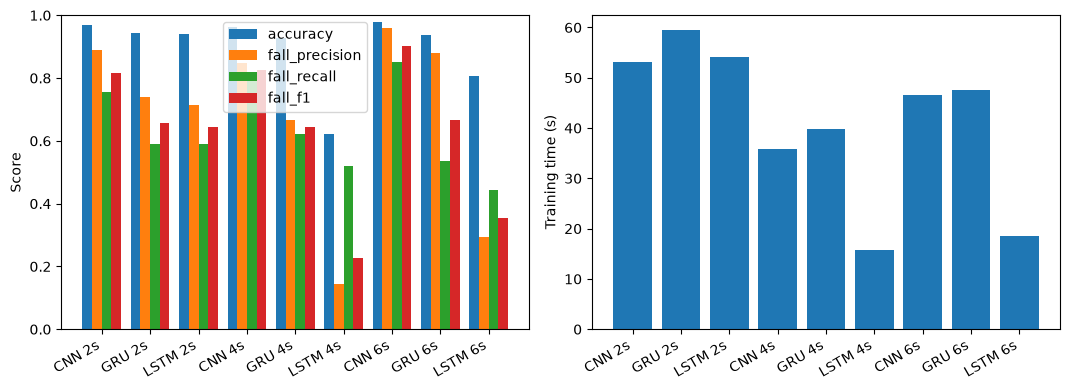

In [21]:
if comparison_rows:
    import matplotlib.pyplot as plt

    labels = [
        f"{row['model']} {row['duration_seconds']}s"
        for row in comparison.iter_rows(named=True)
    ]
    positions = np.arange(len(labels))
    fig, axes = plt.subplots(1, 2, figsize=(max(10, len(labels) * 1.2), 4))
    metrics = ("accuracy", "fall_precision", "fall_recall", "fall_f1")
    width = 0.2
    for offset, name in enumerate(metrics):
        axes[0].bar(
            positions + (offset - 1.5) * width,
            comparison[name].to_numpy(),
            width,
            label=name,
        )
    axes[0].set_xticks(positions, labels, rotation=30, ha="right")
    axes[0].set_ylim(0, 1)
    axes[0].set_ylabel("Score")
    axes[0].legend()
    axes[1].bar(positions, comparison["training_seconds"].to_numpy())
    axes[1].set_xticks(positions, labels, rotation=30, ha="right")
    axes[1].set_ylabel("Training time (s)")
    fig.tight_layout()
    fig.savefig(PYTORCH_RUN / "comparison.png", dpi=150)
    plt.show()

## Reload a saved model

Load a checkpoint from the current full-data run or the pilot and predict one test window.

In [22]:
LOAD_MODEL = "gru"
LOAD_WINDOW_SECONDS = 2

if RUN_FULL_TRAINING or RUN_PILOT:
    if RUN_FULL_TRAINING:
        model_dir = MODEL_RUN / "full" / f"{LOAD_WINDOW_SECONDS}s" / LOAD_MODEL
        load_frame_path = split_path
        load_normalizer_path = (
            MODEL_RUN / "full" / f"normalizer-{LOAD_WINDOW_SECONDS}s.npz"
        )
    elif LOAD_WINDOW_SECONDS == PILOT_DURATION:
        model_dir = MODEL_RUN / "pilot"
        load_frame_path = selection_path
        load_normalizer_path = normalizer_path
    else:
        raise ValueError("The pilot has a checkpoint only for PILOT_DURATION.")

    saved_metrics = json.loads(
        (model_dir / f"{LOAD_MODEL}-{LOAD_WINDOW_SECONDS}s.json").read_text()
    )
    load_device = torch.device(selected_device)
    loaded_model = MODELS[LOAD_MODEL](
        saved_metrics["features"], saved_metrics["config"]["hidden_size"]
    ).to(load_device)
    checkpoint = model_dir / f"{LOAD_MODEL}-{LOAD_WINDOW_SECONDS}s.pt"
    loaded_model.load_state_dict(
        torch.load(checkpoint, map_location=load_device, weights_only=True)
    )
    loaded_model.eval()
    test_frame = pl.read_parquet(load_frame_path).filter(
        (pl.col("duration") == LOAD_WINDOW_SECONDS) & (pl.col("split") == "test")
    )
    test_dataset = SequenceDataset(
        test_frame, Normalizer.load(load_normalizer_path), SegmentStore()
    )
    values, rows = next(test_dataset.batches(1))
    with torch.inference_mode():
        probability = torch.sigmoid(
            loaded_model(torch.from_numpy(values).to(load_device))
        ).item()
    print("Fall probability:", probability, "target:", rows[0]["target"])
else:
    print("Run the pilot or full-data training before reloading a model.")

## Export trained models to ONNX

Run after training, or set `ONNX_RUN` to an existing `artifacts/notebooks/03_training/<run-id>/` directory. Models and normalizers are read from `models/sequence/<run-id>/`; ONNX bundles are written there under `onnx/<mode>/`. Install export dependencies with `uv sync --inexact --extra analysis --extra cuda --extra notebook --extra onnx` (use `detection` instead of `cuda` for CPU). The cell exports available checkpoints on CPU, checks ONNX structure, and compares logits with PyTorch on two held-out windows at batch sizes 1 and 2. Time and feature dimensions are fixed per model; batch size is dynamic from 1 to 128.

Models take the same prepared float32 inputs as training, not raw CSI, and return fall logits. The output folder includes the saved training normalizers and a manifest describing feature order, hashes, and sigmoid scoring. Export uses the current `torch.export`-based ONNX exporter (`dynamo=True`, opset 18), with weights embedded in each file.

In [32]:
import shutil

import onnx
import onnxruntime as ort

# Point this at a previous run to export its saved checkpoints instead.
ONNX_RUN = PYTORCH_RUN
ONNX_MODE = "full" if RUN_FULL_TRAINING else "pilot"
ONNX_MODELS = PROJECT_ROOT / "models/sequence" / ONNX_RUN.name
ONNX_OUTPUT = ONNX_MODELS / "onnx" / ONNX_MODE
onnx_durations = DURATIONS if ONNX_MODE == "full" else (PILOT_DURATION,)
onnx_split_path = (
    ONNX_RUN / "window_split.parquet"
    if ONNX_MODE == "full"
    else ONNX_RUN / "pilot/window_split.parquet"
)
onnx_jobs = []
for seconds in onnx_durations:
    for kind in MODELS:
        folder = (
            ONNX_MODELS / "full" / f"{seconds}s" / kind
            if ONNX_MODE == "full"
            else ONNX_MODELS / "pilot"
        )
        weights_path = folder / f"{kind}-{seconds}s.pt"
        if weights_path.is_file():
            onnx_jobs.append((kind, seconds, folder, weights_path))
        else:
            print("Checkpoint unavailable; skipped:", weights_path)
if not onnx_jobs:
    raise FileNotFoundError(f"No trained checkpoints found in {ONNX_RUN}")

onnx_split = pl.read_parquet(onnx_split_path)
ONNX_OUTPUT.mkdir(parents=True, exist_ok=True)
onnx_exports = []
for kind, seconds, folder, weights_path in onnx_jobs:
    state = torch.load(weights_path, map_location="cpu", weights_only=True)
    features = state["conv1.weight" if kind == "cnn" else "rnn.weight_ih_l0"].shape[1]
    rate = {1960: 96, 1964: 120}[features]
    model = MODELS[kind](features, state["head.weight"].shape[1]).eval()
    model.load_state_dict(state)
    normalizer_source = (
        ONNX_MODELS / "full" / f"normalizer-{seconds}s.npz"
        if ONNX_MODE == "full"
        else ONNX_MODELS / "pilot" / f"normalizer-{seconds}s.npz"
    )
    examples_frame = onnx_split.filter(
        (pl.col("duration") == seconds) & (pl.col("split") == "test")
    ).head(2)
    if len(examples_frame) < 2 or set(examples_frame["rate_hz"]) != {rate}:
        raise ValueError(
            "Export verification requires two test windows at the checkpoint rate"
        )
    example_values, _ = next(
        SequenceDataset(
            examples_frame, Normalizer.load(normalizer_source), SegmentStore()
        ).batches(2)
    )
    examples = torch.from_numpy(example_values)
    onnx_path = ONNX_OUTPUT / f"{kind}-{seconds}s.onnx"
    pending_path = onnx_path.with_suffix(".onnx.tmp")
    # A batch of two avoids specializing the exported batch dimension to one.
    torch.onnx.export(
        model,
        (examples,),
        str(pending_path),
        dynamo=True,
        external_data=False,
        opset_version=18,
        input_names=["input"],
        output_names=["fall_logit"],
        dynamic_shapes=({0: torch.export.Dim("batch", min=1, max=128)},),
    )
    onnx.checker.check_model(onnx.load(pending_path))
    options = ort.SessionOptions()
    options.intra_op_num_threads = CPU_THREADS
    runtime = ort.InferenceSession(
        str(pending_path), sess_options=options, providers=["CPUExecutionProvider"]
    )
    errors = []
    for batch in (1, 2):
        with torch.inference_mode():
            expected = model(examples[:batch]).numpy()
        actual = runtime.run(["fall_logit"], {"input": example_values[:batch]})[0]
        np.testing.assert_allclose(actual, expected, rtol=1e-4, atol=1e-5)
        errors.append(float(np.max(np.abs(actual - expected))))
    pending_path.replace(onnx_path)
    normalizer_target = ONNX_OUTPUT / normalizer_source.name
    shutil.copy2(normalizer_source, normalizer_target)
    onnx_exports.append(
        {
            "model": kind,
            "duration_seconds": seconds,
            "sample_rate_hz": rate,
            "file": onnx_path.name,
            "sha256": hashlib.sha256(onnx_path.read_bytes()).hexdigest(),
            "checkpoint_sha256": hashlib.sha256(weights_path.read_bytes()).hexdigest(),
            "normalizer": normalizer_target.name,
            "normalizer_sha256": hashlib.sha256(
                normalizer_target.read_bytes()
            ).hexdigest(),
            "input_shape": ["batch", seconds * rate, features],
            "maximum_absolute_logit_error": max(errors),
        }
    )
    print(f"Verified {onnx_path.name}; max logit error {max(errors):.3g}")
(ONNX_OUTPUT / "manifest.json").write_text(
    json.dumps(
        {
            "opset": 18,
            "torch_version": torch.__version__,
            "onnx_version": onnx.__version__,
            "onnxruntime_version": ort.__version__,
            "input_name": "input",
            "input_dtype": "float32",
            "input_layout": "batch,time,features",
            "feature_order": "980 normalized signals, 980 validity flags, then 4 presence flags at 120 Hz",
            "preprocessing": "Use the same signal preprocessing and saved training normalizer; preprocessing is not embedded in ONNX.",
            "output_name": "fall_logit",
            "output_shape": ["batch"],
            "score": "sigmoid(fall_logit); threshold 0.5",
            "verification_batch_sizes": [1, 2],
            "batch_size_range": [1, 128],
            "exporter": "torch.export",
            "split_sha256": hashlib.sha256(onnx_split_path.read_bytes()).hexdigest(),
            "exports": onnx_exports,
        },
        indent=2,
    )
    + "\n"
)
print("ONNX exports:", ONNX_OUTPUT)